# UCS420: Cognitive Computing - Assignment 10
## Heart Health Information Assistant (Healthcare Cognitive Assistant)

**Name:** Arshpreet Singh  
**Roll No:** 1024170170 (even roll number -> Heart Health Information Assistant)

**Pipeline:** User query -> NLP pre-processing -> TF-IDF + Logistic Regression intent classifier -> rule-based reasoning (emergency / unsupported / low-confidence / safety) -> knowledge-base retrieval -> response

> Disclaimer: this assistant gives general educational information only. It is not a substitute for professional medical advice, diagnosis or treatment.

In [1]:
!pip -q install scikit-learn nltk networkx ipywidgets seaborn

In [2]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import nltk
from nltk.tokenize import RegexpTokenizer
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Libraries loaded')

Libraries loaded


## 1. Labelled corpus (>= 40 queries, >= 5 intents)
6 intents x 16 queries = 96 labelled queries about heart health.

In [3]:
corpus = {
 'symptoms': [
  "What are the common symptoms of heart disease?",
  "What are the warning signs of a heart attack?",
  "Why do I feel palpitations and a racing heartbeat?",
  "Is shortness of breath a symptom of heart problems?",
  "What does angina feel like?",
  "Can swollen ankles and fatigue be symptoms of heart failure?",
  "What are the early signs of a weak heart?",
  "Do dizziness and fainting relate to heart conditions?",
  "How do heart attack symptoms differ in women?",
  "What does chest discomfort mean?",
  "Which symptoms show that my heart is not working properly?",
  "Is a fluttering heartbeat a sign of arrhythmia?",
  "What are the symptoms of heart failure?",
  "Why do I get tired and breathless on climbing stairs?",
  "What are the signs of a silent heart attack?",
  "Does pain in the left arm or jaw indicate a heart problem?"],
 'risk_factors': [
  "What are the risk factors for heart disease?",
  "Does smoking increase the risk of a heart attack?",
  "Is high cholesterol a risk for my heart?",
  "Does family history increase my risk of cardiovascular disease?",
  "How does high blood pressure raise heart disease risk?",
  "Are obesity and a sedentary lifestyle risk factors for heart disease?",
  "Does stress increase the risk of heart problems?",
  "At what age does the risk of heart disease increase?",
  "Does excessive alcohol raise heart disease risk?",
  "Who is at higher risk of getting a heart attack?",
  "Does diabetes make heart disease more likely?",
  "Why are men at more risk of heart disease than women?",
  "Is genetics a risk factor for heart disease?",
  "What causes heart disease?",
  "Does air pollution increase cardiovascular risk?",
  "How does smoking cause damage to the arteries?"],
 'prevention_lifestyle': [
  "How can I keep my heart healthy?",
  "How can I prevent heart disease?",
  "What exercises are good for the heart?",
  "How much physical activity do I need each week to prevent heart disease?",
  "How does quitting smoking help my heart?",
  "Can yoga and meditation improve cardiovascular health?",
  "How can I lower stress to protect my heart?",
  "How many hours of sleep are best for a healthy heart?",
  "What lifestyle changes prevent a heart attack?",
  "Is walking every day good exercise for the heart?",
  "How can I reduce my chances of getting heart disease?",
  "How do I maintain a healthy weight for my heart?",
  "Which habits protect the heart?",
  "Does regular exercise strengthen the heart?",
  "What can I do daily to lower my risk of heart disease?",
  "Is cycling or swimming good for my cardiovascular fitness?"],
 'diagnosis_tests': [
  "What tests are used to diagnose heart disease?",
  "What is an ECG and why is it done?",
  "How does an echocardiogram work?",
  "What is a cardiac stress test?",
  "What does a lipid profile blood test measure?",
  "When should I get my cholesterol checked?",
  "How is blood pressure measured and what is a normal reading?",
  "What is an angiography test?",
  "Which doctor should I see for a heart checkup?",
  "How is a heart attack diagnosed in hospital?",
  "What is a troponin blood test?",
  "What is a Holter monitor test?",
  "Which test checks the electrical activity of the heart?",
  "How do doctors check for blocked arteries?",
  "What is a CT scan of the heart?",
  "How often should I have a heart checkup?"],
 'treatment_medication': [
  "How is heart disease treated?",
  "What medicines are used for high blood pressure?",
  "What are statins and how do they work?",
  "What is angioplasty and when is it needed?",
  "Why are beta blockers prescribed for heart patients?",
  "What is bypass surgery?",
  "What is the role of aspirin in treatment of heart attack?",
  "What is cardiac rehabilitation after a heart attack?",
  "What are the side effects of heart medication?",
  "Which medicines are given after a heart attack?",
  "What is a stent and how is it placed?",
  "What is a pacemaker and who needs one?",
  "How are blood thinners used to treat heart conditions?",
  "What drugs treat heart failure?",
  "When is surgery needed for a blocked artery?",
  "What is the treatment for an irregular heartbeat?"],
 'diet_nutrition': [
  "What foods are good for the heart?",
  "What diet should I follow for a healthy heart?",
  "Is salt bad for blood pressure?",
  "Which foods should I avoid with high cholesterol?",
  "Are eggs and red meat bad for the heart?",
  "Does the Mediterranean diet help cardiovascular health?",
  "How much fibre and omega-3 should I eat for my heart?",
  "Are fried and processed foods bad for my arteries?",
  "Is it okay to drink coffee with heart problems?",
  "Which fruits and vegetables are best for heart health?",
  "Is olive oil better than butter for the heart?",
  "Should I eat less sugar and fat to protect my heart?",
  "Are nuts and fish good to eat for the heart?",
  "What should I eat to lower cholesterol?",
  "What is the DASH diet?",
  "How much salt can I eat each day with heart disease?"],
}
rows = [(q, intent) for intent, qs in corpus.items() for q in qs]
df = pd.DataFrame(rows, columns=['query', 'intent'])
print('Total queries:', len(df), '| Intents:', df.intent.nunique())
print(df.intent.value_counts())
df.sample(8, random_state=1)

Total queries: 96 | Intents: 6
intent
symptoms                16
risk_factors            16
prevention_lifestyle    16
diagnosis_tests         16
treatment_medication    16
diet_nutrition          16
Name: count, dtype: int64


,query,intent
40,What lifestyle changes prevent a heart attack?,prevention_lifestyle
31,How does smoking cause damage to the arteries?,risk_factors
46,What can I do daily to lower my risk of heart ...,prevention_lifestyle
59,What is a Holter monitor test?,diagnosis_tests
78,When is surgery needed for a blocked artery?,treatment_medication
74,What is a stent and how is it placed?,treatment_medication
65,What medicines are used for high blood pressure?,treatment_medication
44,Which habits protect the heart?,prevention_lifestyle


## 2. Hierarchical taxonomy (4 major categories, 2+ subcategories each)
Each leaf of the taxonomy is mapped to the intent used by the classifier.

In [4]:
taxonomy = {
 'Clinical Presentation': {
    'Symptoms & Warning Signs': 'symptoms',
    'Heart Conditions (CAD, heart failure, arrhythmia)': 'symptoms'},
 'Risk & Prevention': {
    'Risk Factors': 'risk_factors',
    'Healthy Lifestyle & Prevention': 'prevention_lifestyle'},
 'Diagnosis & Treatment': {
    'Diagnostic Tests': 'diagnosis_tests',
    'Medicines & Procedures': 'treatment_medication'},
 'Nutrition': {
    'Heart-Healthy Foods': 'diet_nutrition',
    'Foods to Limit (salt, saturated fat)': 'diet_nutrition'},
}
def print_taxonomy(t):
    print('Heart Health')
    for major, subs in t.items():
        print(' |--', major)
        for sub, intent in subs.items():
            print(' |    |--', sub, f'  [intent: {intent}]')
print_taxonomy(taxonomy)
print('\nMajor categories:', len(taxonomy), '| Subcategories:', sum(len(v) for v in taxonomy.values()))

Heart Health
 |-- Clinical Presentation
 |    |-- Symptoms & Warning Signs   [intent: symptoms]
 |    |-- Heart Conditions (CAD, heart failure, arrhythmia)   [intent: symptoms]
 |-- Risk & Prevention
 |    |-- Risk Factors   [intent: risk_factors]
 |    |-- Healthy Lifestyle & Prevention   [intent: prevention_lifestyle]
 |-- Diagnosis & Treatment
 |    |-- Diagnostic Tests   [intent: diagnosis_tests]
 |    |-- Medicines & Procedures   [intent: treatment_medication]
 |-- Nutrition
 |    |-- Heart-Healthy Foods   [intent: diet_nutrition]
 |    |-- Foods to Limit (salt, saturated fat)   [intent: diet_nutrition]

Major categories: 4 | Subcategories: 8


## 3. Domain concepts and relationships (>= 8 concepts, >= 10 relationships)

12 concepts, 12 relationships


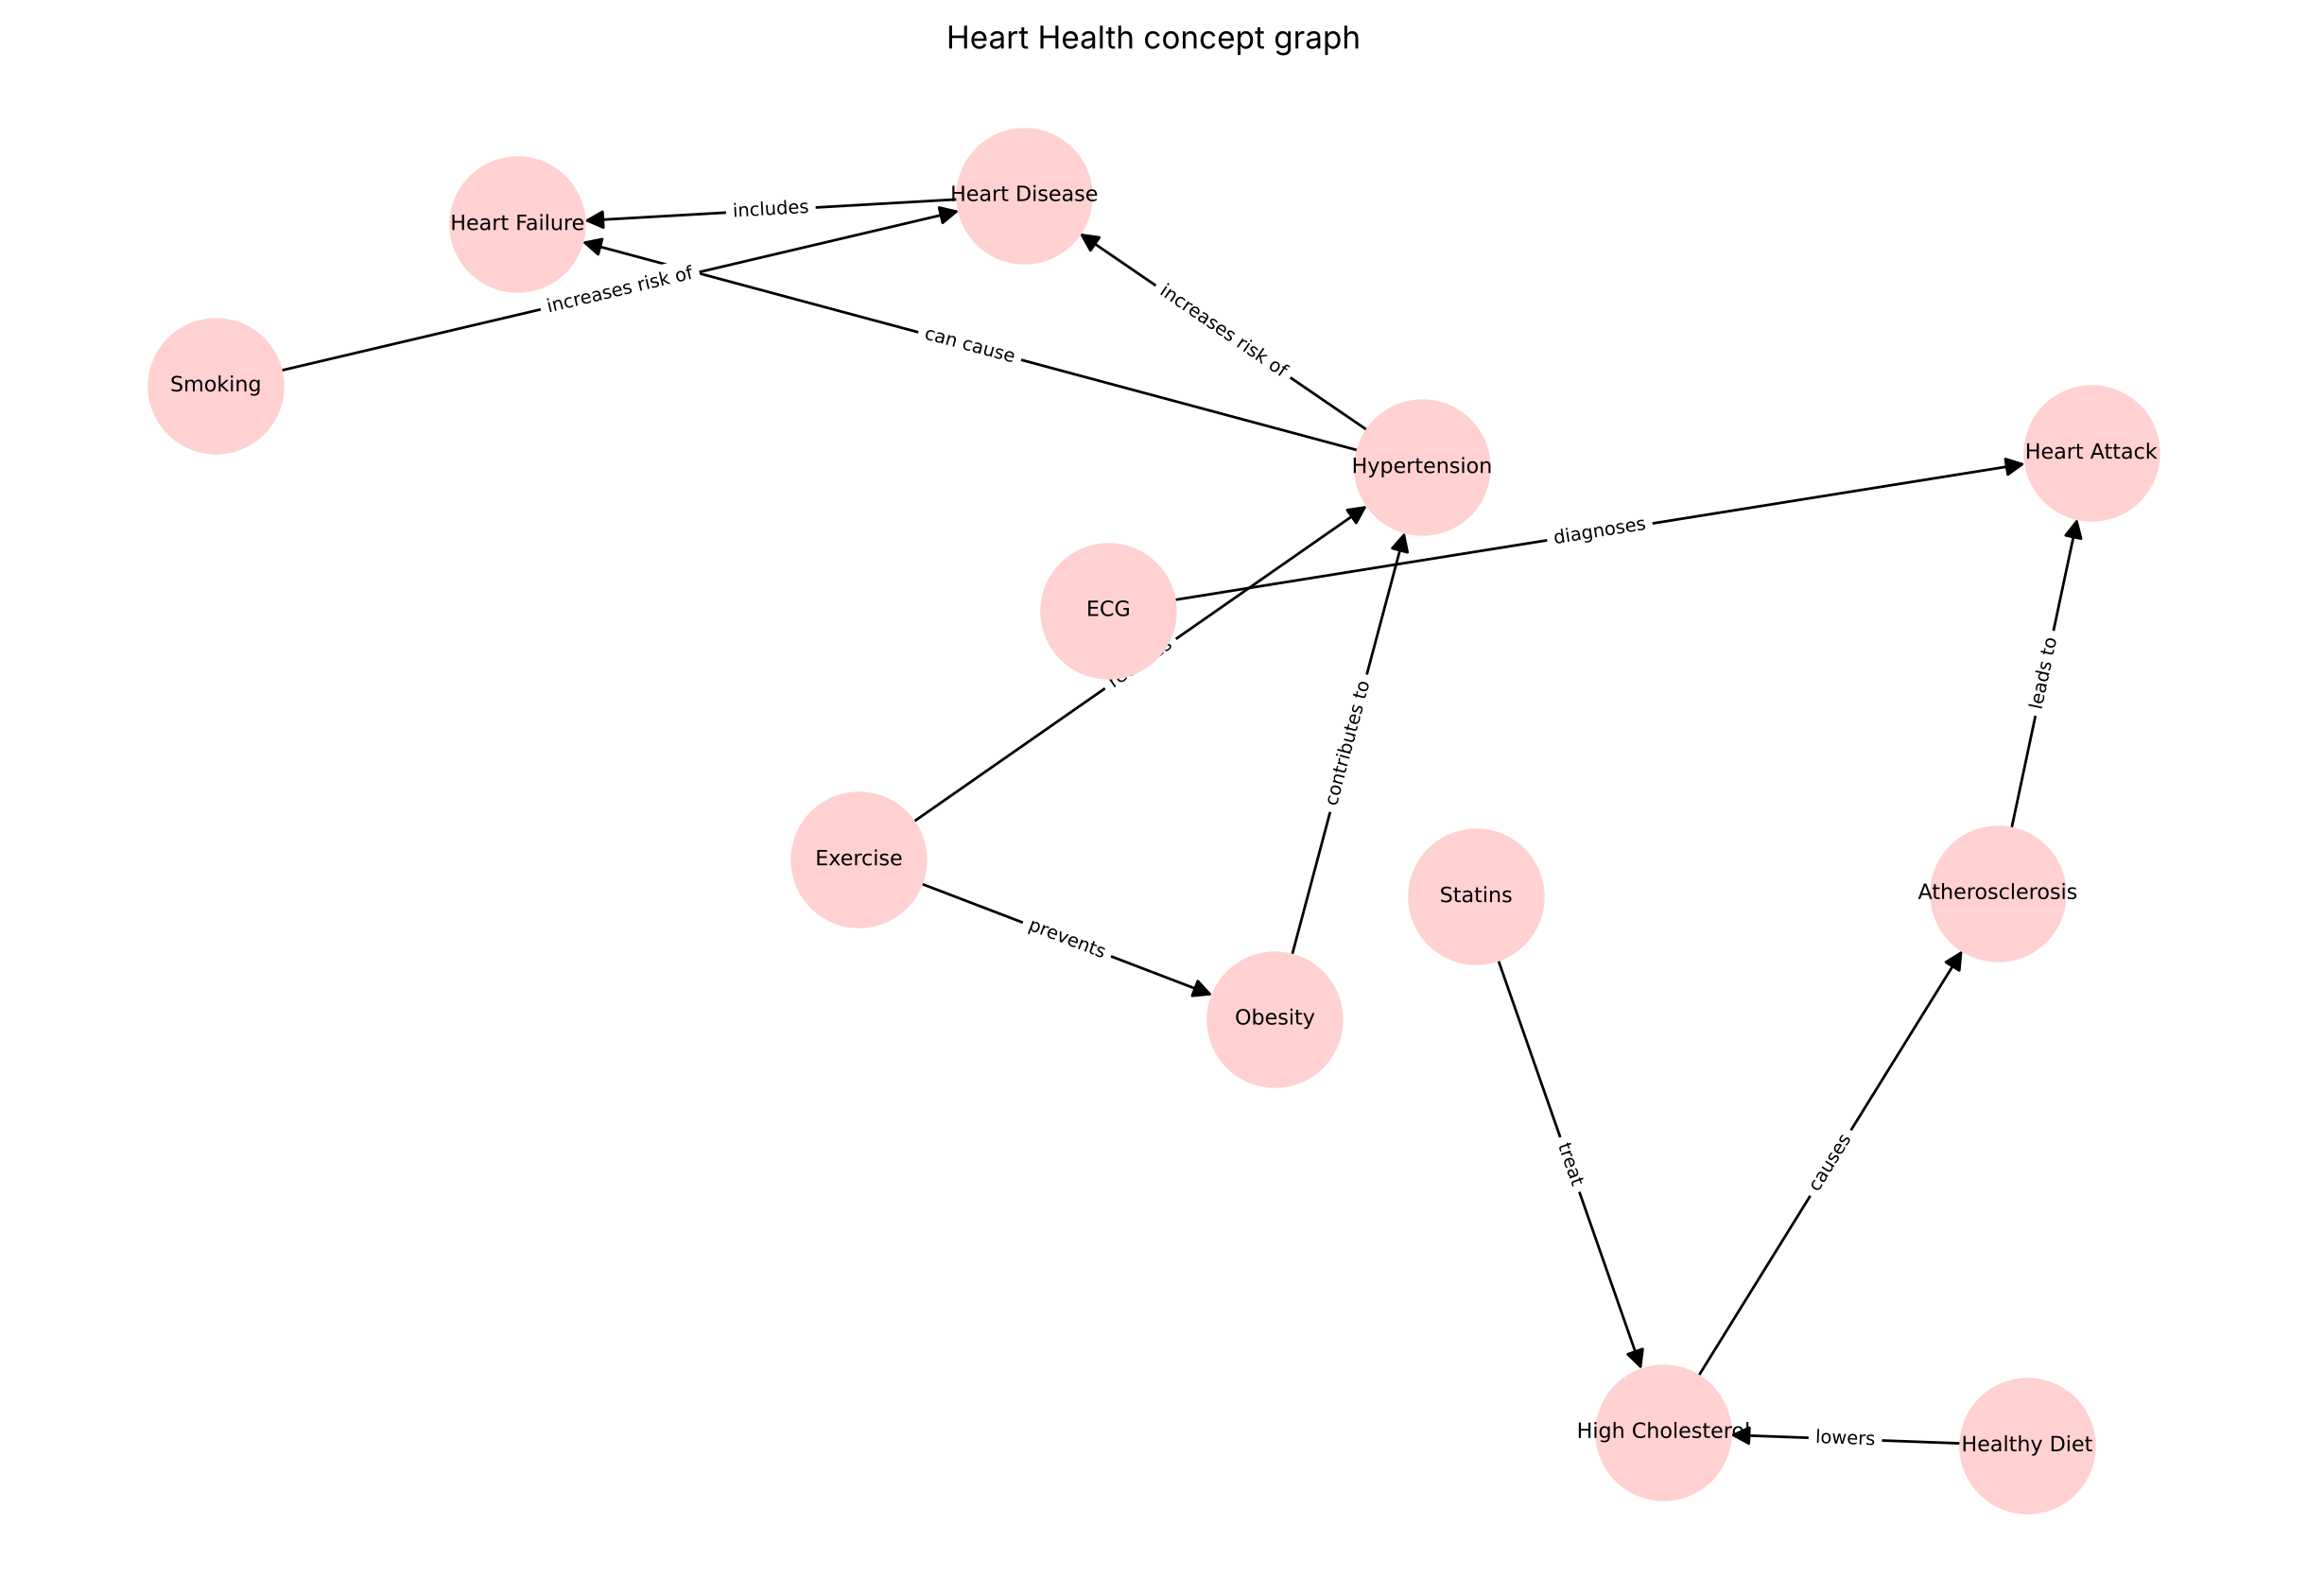

In [5]:
concepts = ['Heart Disease', 'Hypertension', 'High Cholesterol', 'Smoking', 'Obesity',
            'Atherosclerosis', 'Heart Attack', 'Heart Failure', 'Exercise', 'Healthy Diet',
            'Statins', 'ECG']
relationships = [
 ('Smoking', 'increases risk of', 'Heart Disease'),
 ('Hypertension', 'increases risk of', 'Heart Disease'),
 ('High Cholesterol', 'causes', 'Atherosclerosis'),
 ('Atherosclerosis', 'leads to', 'Heart Attack'),
 ('Obesity', 'contributes to', 'Hypertension'),
 ('Hypertension', 'can cause', 'Heart Failure'),
 ('Exercise', 'reduces', 'Hypertension'),
 ('Healthy Diet', 'lowers', 'High Cholesterol'),
 ('Statins', 'treat', 'High Cholesterol'),
 ('ECG', 'diagnoses', 'Heart Attack'),
 ('Heart Disease', 'includes', 'Heart Failure'),
 ('Exercise', 'prevents', 'Obesity'),
]
print(len(concepts), 'concepts,', len(relationships), 'relationships')
G = nx.DiGraph()
for s, r, o in relationships:
    G.add_edge(s, o, label=r)
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, seed=7, k=1.1)
nx.draw(G, pos, with_labels=True, node_color='#ffd1d1', node_size=2600, font_size=8, arrowsize=15)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, 'label'), font_size=7)
plt.title('Heart Health concept graph'); plt.show()

## 4. NLP pre-processing
Lowercase -> tokenize -> stopword removal -> lemmatization.  
NLTK (WordNet lemmatizer and stopwords) is used when its data can be downloaded; otherwise a built-in rule-based fallback is used so the notebook always runs. Negations ("no", "not") are kept because they matter in medical text.

In [6]:
tokenizer = RegexpTokenizer(r"[a-z]+")

# ---- stopwords ----
KEEP = {'no', 'not', 'nor'}
try:
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    STOP = set(stopwords.words('english')) - KEEP
    STOP_SRC = 'NLTK'
except Exception:
    STOP = set(ENGLISH_STOP_WORDS) - KEEP
    STOP_SRC = 'sklearn fallback'
# generic question words carry no intent information
STOP |= {'what', 'which', 'how', 'why', 'when', 'can', 'does', 'do', 'is', 'are', 'should', 'would'}
# 'heart' and 'health' appear in almost every query of this domain, so it carries no intent information
STOP |= {'heart', 'health'}

# ---- lemmatizer ----
IRREGULAR = {'feet': 'foot', 'men': 'man', 'women': 'woman', 'was': 'be', 'were': 'be', 'has': 'have',
             'does': 'do', 'diagnosed': 'diagnose', 'smoking': 'smoke', 'exercising': 'exercise'}
def fallback_lemma(w):
    if w in IRREGULAR: return IRREGULAR[w]
    if len(w) > 4 and w.endswith('ies'): return w[:-3] + 'y'
    if len(w) > 4 and w.endswith(('sses', 'xes', 'ches', 'shes')): return w[:-2]
    if len(w) > 3 and w.endswith('s') and not w.endswith(('ss', 'us', 'is')): return w[:-1]
    if len(w) > 5 and w.endswith('ing'): return w[:-3]
    if len(w) > 4 and w.endswith('ed'): return w[:-2]
    return w

try:
    nltk.download('wordnet', quiet=True)
    from nltk.stem import WordNetLemmatizer
    _wnl = WordNetLemmatizer()
    _wnl.lemmatize('tests')                      # raises LookupError if data is missing
    def lemma(w):
        return _wnl.lemmatize(_wnl.lemmatize(w, 'n'), 'v')
    LEMMA_SRC = 'NLTK WordNet'
except Exception:
    lemma = fallback_lemma
    LEMMA_SRC = 'rule-based fallback'
print('Stopwords:', STOP_SRC, '| Lemmatizer:', LEMMA_SRC)

def preprocess(text, return_steps=False):
    lower = text.lower()                                   # 1. lowercase
    tokens = tokenizer.tokenize(lower)                     # 2. tokenization
    no_stop = [t for t in tokens if t not in STOP]         # 3. stopword removal
    lemmas = [lemma(t) for t in no_stop]                   # 4. lemmatization
    if return_steps:
        return lower, tokens, no_stop, lemmas
    return ' '.join(lemmas)

demo = "What are the warning signs of Heart Attacks in women?"
for name, out in zip(['Lowercase', 'Tokens', 'No stopwords', 'Lemmas'], preprocess(demo, True)):
    print(f'{name:13s}:', out)
df['clean'] = df['query'].apply(preprocess)
df.head()

Stopwords: sklearn fallback | Lemmatizer: rule-based fallback
Lowercase    : what are the warning signs of heart attacks in women?
Tokens       : ['what', 'are', 'the', 'warning', 'signs', 'of', 'heart', 'attacks', 'in', 'women']
No stopwords : ['warning', 'signs', 'attacks', 'women']
Lemmas       : ['warn', 'sign', 'attack', 'woman']


,query,intent,clean
0,What are the common symptoms of heart disease?,symptoms,common symptom disease
1,What are the warning signs of a heart attack?,symptoms,warn sign attack
2,Why do I feel palpitations and a racing heartb...,symptoms,feel palpitation rac heartbeat
3,Is shortness of breath a symptom of heart prob...,symptoms,shortness breath symptom problem
4,What does angina feel like?,symptoms,angina feel like


## 5. TF-IDF feature extraction + Logistic Regression classifier

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df['query'], df['intent'], test_size=0.25, stratify=df['intent'], random_state=42)

clf = Pipeline([
    ('tfidf', TfidfVectorizer(preprocessor=None, tokenizer=lambda s: s.split(),
                              token_pattern=None, lowercase=False, ngram_range=(1, 1), sublinear_tf=True)),
    ('lr', LogisticRegression(C=10, max_iter=2000)),
])
# apply NLP pipeline before TF-IDF
clf.fit(X_train.apply(preprocess), y_train)

vec = clf.named_steps['tfidf']
print('Vocabulary size:', len(vec.vocabulary_))
print('Train size:', len(X_train), '| Test size:', len(X_test))

# Top TF-IDF-weighted terms per intent
lr = clf.named_steps['lr']; terms = np.array(vec.get_feature_names_out())
for i, c in enumerate(lr.classes_):
    print(f'{c:22s}:', ', '.join(terms[np.argsort(lr.coef_[i])[-5:][::-1]]))

Vocabulary size: 149
Train size: 72 | Test size: 24
diagnosis_tests       : test, checkup, check, ecg, diagnose
diet_nutrition        : eat, food, diet, salt, vegetable
prevention_lifestyle  : prevent, healthy, exercise, protect, lower
risk_factors          : risk, cause, disease, factor, high
symptoms              : symptom, sign, feel, mean, discomfort
treatment_medication  : treat, treatment, statin, angioplasty, surgery


## 6. Evaluation: accuracy, precision, recall, F1, confusion matrix

Accuracy : 0.708
Precision: 0.731 (weighted)
Recall   : 0.708 (weighted)
F1-score : 0.706 (weighted)

                      precision    recall  f1-score   support

     diagnosis_tests       1.00      0.75      0.86         4
      diet_nutrition       0.50      0.75      0.60         4
prevention_lifestyle       0.67      0.50      0.57         4
        risk_factors       0.80      1.00      0.89         4
            symptoms       0.75      0.75      0.75         4
treatment_medication       0.67      0.50      0.57         4

            accuracy                           0.71        24
           macro avg       0.73      0.71      0.71        24
        weighted avg       0.73      0.71      0.71        24



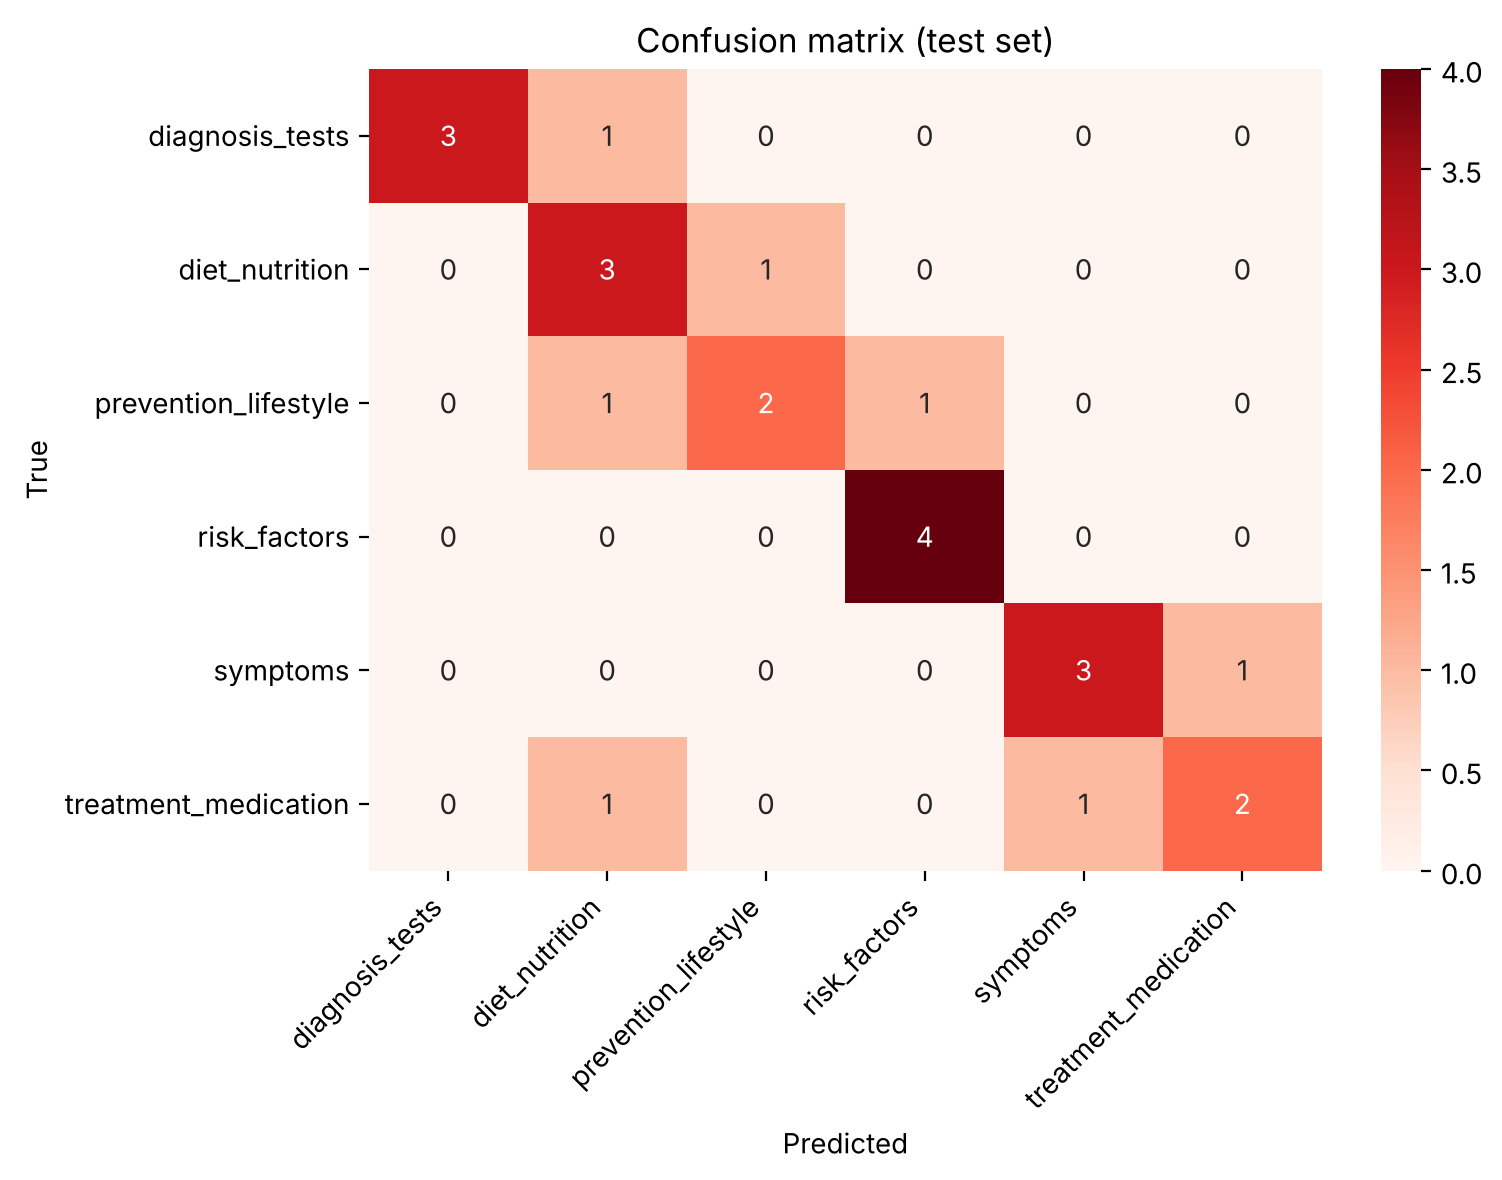

5-fold CV accuracy: 0.750 +/- 0.084


In [8]:
y_pred = clf.predict(X_test.apply(preprocess))
acc = accuracy_score(y_test, y_pred)
p, r, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='weighted', zero_division=0)
print(f'Accuracy : {acc:.3f}')
print(f'Precision: {p:.3f} (weighted)')
print(f'Recall   : {r:.3f} (weighted)')
print(f'F1-score : {f1:.3f} (weighted)\n')
print(classification_report(y_test, y_pred, zero_division=0))

labels = sorted(df.intent.unique())
cm = confusion_matrix(y_test, y_pred, labels=labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test set)'); plt.xticks(rotation=45, ha='right')
plt.tight_layout(); plt.show()

# 5-fold cross validation gives a more reliable estimate on a small corpus
cv = StratifiedKFold(5, shuffle=True, random_state=42)
scores = cross_val_score(clf, df['query'].apply(preprocess), df['intent'], cv=cv)
print(f'5-fold CV accuracy: {scores.mean():.3f} +/- {scores.std():.3f}')

## 7. Domain-specific knowledge base
One entry per intent (plus a follow-up suggestion), written from general, widely accepted heart-health guidance.

In [9]:
knowledge_base = {
 'symptoms': {
   'title': 'Heart disease symptoms and warning signs',
   'info': ("Common symptoms include chest pain or pressure (angina), shortness of breath, palpitations, "
            "unusual fatigue, dizziness or fainting, and swelling in the legs, ankles or feet. Women may have "
            "less typical symptoms such as nausea, jaw or back pain and extreme tiredness. Symptoms that come on "
            "suddenly or are severe need urgent medical attention."),
   'followup': 'Would you like to know which tests help diagnose these symptoms?'},
 'risk_factors': {
   'title': 'Heart disease risk factors',
   'info': ("Major modifiable risk factors are high blood pressure, high LDL cholesterol, smoking, diabetes, obesity, "
            "physical inactivity, unhealthy diet, excess alcohol and chronic stress. Non-modifiable factors include "
            "age, sex and family history of early heart disease."),
   'followup': 'Would you like tips on lowering your risk?'},
 'prevention_lifestyle': {
   'title': 'Preventing heart disease and staying heart-healthy',
   'info': ("Aim for at least 150 minutes of moderate exercise a week, do not smoke, maintain a healthy weight, "
            "sleep 7-9 hours, manage stress (yoga, meditation, hobbies), limit alcohol and go for regular health checkups. "
            "Small consistent changes make a big difference."),
   'followup': 'Would you like diet suggestions as well?'},
 'diagnosis_tests': {
   'title': 'Tests used to check heart health',
   'info': ("Common tests: ECG (records the heart's electrical activity), echocardiogram (ultrasound of the heart), "
            "stress test (heart under exercise), lipid profile (cholesterol and triglycerides), blood pressure "
            "measurement (normal is roughly below 120/80 mmHg), cardiac blood tests such as troponin, and coronary "
            "angiography to see blocked arteries. A cardiologist decides which tests you need."),
   'followup': 'Would you like to know how heart conditions are treated?'},
 'treatment_medication': {
   'title': 'Heart disease treatment and medicines',
   'info': ("Treatment combines lifestyle change, medicines and procedures. Common medicines: statins (lower cholesterol), "
            "beta blockers and ACE inhibitors (lower blood pressure and heart workload), antiplatelets such as aspirin "
            "(reduce clot risk) and diuretics. Procedures include angioplasty with stent and bypass surgery, followed "
            "by cardiac rehabilitation. Never start, stop or change a medicine without your doctor's advice."),
   'followup': 'Would you like diet advice that supports your treatment?'},
 'diet_nutrition': {
   'title': 'Heart-healthy diet',
   'info': ("Favour vegetables, fruits, whole grains, legumes, nuts, fish rich in omega-3 and healthy oils. "
            "Limit salt (under about 5 g per day), saturated and trans fats, red and processed meat, fried food, sugary "
            "drinks and excess alcohol. A Mediterranean-style or DASH diet is well studied for heart health."),
   'followup': 'Would you like exercise suggestions too?'},
}
emergency_info = {
  'title': 'POSSIBLE MEDICAL EMERGENCY',
  'info': ("Call your local emergency number IMMEDIATELY (112 or 108 in India, 911 in the US, 999 in the UK) or go to the nearest "
           "emergency room. Do not drive yourself. Sit or lie down, stay calm, loosen tight clothing, and if a doctor has "
           "not told you otherwise and you are not allergic, chewing one regular aspirin may help while you wait for help.")}
print('Knowledge base entries:', len(knowledge_base), 'intents + emergency protocol')

Knowledge base entries: 6 intents + emergency protocol


## 8. Reasoning rules (>= 5)
| # | Rule | Action |
|---|------|--------|
| R1 | Emergency keywords/patterns (chest pain + radiating/sweating, cannot breathe, fainted, stroke signs ...) | Escalate to emergency protocol, skip classifier |
| R2 | Query is about another disease/topic (diabetes, cancer, dental, covid ...) | Unsupported-query response |
| R3 | None of the words are in the model vocabulary | Unsupported / out-of-domain response |
| R4 | Max class probability < threshold, or the top two intents are too close | Low-confidence: ask the user to rephrase and suggest topics |
| R5 | Query asks about medicine dosage or stopping/starting a drug | Add medication safety warning |
| R6 | Query asks "do I have..." / personal diagnosis | Add "cannot diagnose" disclaimer |
| R7 | Greeting / thanks / goodbye | Friendly small-talk reply |

In [10]:
CONF_THRESHOLD = 0.45     # minimum top-class probability
MARGIN_THRESHOLD = 0.12   # minimum gap between best and second-best class

EMERGENCY_PATTERNS = [
  r"chest (pain|pressure|tightness).*(arm|jaw|sweat|breath|nausea|severe|crushing|now)",
  r"(severe|crushing|sudden|intense).*(chest pain|chest pressure)",
  r"(having|got|suffering).*(heart attack|stroke|cardiac arrest)",
  r"(heart attack|stroke|cardiac arrest).*(right now|happening|now)",
  r"(cannot|can't|can not|unable to|difficulty).*(breathe|breathing)",
  r"(fainted|passed out|collapsed|unconscious|unresponsive)",
  r"(face drooping|slurred speech|sudden weakness|numbness on one side)",
  r"(call|need) (an )?ambulance",
  r"(severe|sudden).*(shortness of breath)",
]
UNSUPPORTED_TOPICS = {
  'diabetes': ['diabetes', 'diabetic', 'blood sugar', 'insulin', 'glucose'],
  'cancer': ['cancer', 'tumor', 'tumour', 'chemotherapy'],
  'dental': ['tooth', 'teeth', 'dental', 'gum'],
  'mental health': ['depression', 'anxiety disorder', 'schizophrenia'],
  'skin': ['acne', 'eczema', 'psoriasis', 'rash'],
  'infection': ['covid', 'flu', 'fever', 'malaria', 'dengue'],
  'other organs / conditions': ['toothache', 'headache', 'migraine', 'stomach', 'kidney', 'liver', 'asthma', 'thyroid', 'arthritis', 'eye', 'back pain'],
  'pregnancy': ['pregnancy', 'pregnant'],
  'non-health': ['weather', 'football', 'cricket', 'movie', 'stock', 'recipe for', 'capital of'],
}
SMALL_TALK = {
  r"^(hi|hello|hey|good (morning|afternoon|evening))\b": "Hello! I am your Heart Health Information Assistant. Ask me about symptoms, risk factors, prevention, tests, treatment or diet for a healthy heart.",
  r"\b(thanks|thank you|thx)\b": "You're welcome! Take care of your heart. Ask me anything else about heart health.",
  r"^(bye|goodbye|see you|exit|quit)\b": "Goodbye! Stay heart-healthy and see a doctor for any concerns.",
}
MED_WORDS = r"\b(dose|dosage|how many (mg|tablets|pills)|stop taking|skip|increase|reduce|start taking|replace)\b"
PERSONAL_DX = r"\b(do i have|am i having|do you think i have|diagnose me|is it my heart|am i at risk)\b"
DISCLAIMER = "Note: this is general educational information, not medical advice. Please consult a doctor for personal concerns."

def vocab_overlap(text):
    toks = preprocess(text).split()
    return sum(t in vec.vocabulary_ for t in toks), len(toks)

## 9. Integrated Heart Health Cognitive Assistant
NLP -> rules -> intent classification -> knowledge retrieval -> response generation, in one class.

In [11]:
class HeartHealthAssistant:
    def __init__(self, model, kb, threshold=CONF_THRESHOLD):
        self.model, self.kb, self.threshold = model, kb, threshold

    def classify(self, query):
        probs = self.model.predict_proba([preprocess(query)])[0]
        i = int(np.argmax(probs))
        return self.model.classes_[i], float(probs[i]), dict(zip(self.model.classes_, probs))

    def respond(self, query):
        q = query.strip()
        result = {'query': q, 'intent': None, 'confidence': None, 'rule': None, 'response': ''}
        low = q.lower()

        # R7 small talk
        for pat, reply in SMALL_TALK.items():
            if re.search(pat, low):
                result.update(rule='R7 small talk', response=reply); return result

        # R1 emergency escalation (highest priority)
        if any(re.search(p, low) for p in EMERGENCY_PATTERNS):
            e = emergency_info
            result.update(rule='R1 emergency escalation',
                          response=f"*** {e['title']} ***\n{e['info']}"); return result

        # R2 unsupported healthcare topic
        for topic, kws in UNSUPPORTED_TOPICS.items():
            if any(re.search(r'\b' + re.escape(k) + r'\b', low) for k in kws):
                result.update(rule='R2 unsupported query',
                              response=(f"Sorry, I can only answer heart health questions. Your question looks like it is about "
                                        f"'{topic}', which I do not cover. Please consult a doctor or a suitable health resource. "
                                        "You can ask me about heart symptoms, risk factors, prevention, tests, treatment or diet."))
                return result

        # R3 out of vocabulary
        known, total = vocab_overlap(q)
        if total == 0 or known == 0:
            result.update(rule='R3 out-of-domain / unknown words',
                          response="I could not relate your question to heart health. Could you ask about heart symptoms, risks, prevention, tests, treatment or diet?")
            return result

        intent, conf, allp = self.classify(q)
        second = sorted(allp.values())[-2]
        result.update(intent=intent, confidence=round(conf, 3))

        # R4 low confidence
        if conf < self.threshold or (conf - second) < MARGIN_THRESHOLD:
            result.update(rule='R4 low confidence',
                          response=(f"I am not sure what you mean (confidence {conf:.0%}). Could you rephrase? "
                                    "For example: 'What are the symptoms of a heart attack?' or 'Which foods are good for my heart?'"))
            return result

        entry = self.kb[intent]
        parts = [f"[{entry['title']}]", entry['info'], entry['followup']]
        rules = ['Intent classified + KB retrieval']
        # R5 medication safety
        if re.search(MED_WORDS, low):
            parts.append("WARNING: Do not change, skip or stop any medicine on your own. Dosage must be decided by your doctor or pharmacist.")
            rules.append('R5 medication safety')
        # R6 personal diagnosis
        if re.search(PERSONAL_DX, low):
            parts.append("I cannot diagnose you. If you are worried about your own heart, please see a doctor.")
            rules.append('R6 no-diagnosis disclaimer')
        parts.append(DISCLAIMER)
        result.update(rule=' + '.join(rules), response='\n'.join(parts))
        return result

# Final model trained on ALL labelled data for deployment
final_model = Pipeline([
    ('tfidf', TfidfVectorizer(tokenizer=lambda s: s.split(), token_pattern=None, lowercase=False,
                              ngram_range=(1, 1), sublinear_tf=True)),
    ('lr', LogisticRegression(C=10, max_iter=2000)),
]).fit(df['query'].apply(preprocess), df['intent'])
vec = final_model.named_steps['tfidf']            # used by the out-of-vocabulary rule
assistant = HeartHealthAssistant(final_model, knowledge_base)
print('Assistant ready')

Assistant ready


## 10. Testing the assistant
Required tests: (1) a query for each intent, (2) a differently worded query, (3) an unsupported healthcare query, (4) a low-confidence query, (5) an emergency query.

In [12]:
def show(res):
    print('Q       :', res['query'])
    print('Intent  :', res['intent'], '| Confidence:', res['confidence'], '| Rule:', res['rule'])
    print('Response:', res['response'])
    print('-' * 100)

print('=== TEST 1: one query per intent ===')
test1 = ["What symptoms should make me suspect a heart problem?",
         "Which risk factors raise the chance of cardiovascular disease?",
         "How can I protect my heart through exercise and lifestyle?",
         "Which test checks the electrical activity of my heart?",
         "Which medicines are given after a heart attack?",
         "What should I eat to keep my heart healthy?"]
for q in test1: show(assistant.respond(q))

=== TEST 1: one query per intent ===
Q       : What symptoms should make me suspect a heart problem?
Intent  : symptoms | Confidence: 0.755 | Rule: Intent classified + KB retrieval
Response: [Heart disease symptoms and warning signs]
Common symptoms include chest pain or pressure (angina), shortness of breath, palpitations, unusual fatigue, dizziness or fainting, and swelling in the legs, ankles or feet. Women may have less typical symptoms such as nausea, jaw or back pain and extreme tiredness. Symptoms that come on suddenly or are severe need urgent medical attention.
Would you like to know which tests help diagnose these symptoms?
Note: this is general educational information, not medical advice. Please consult a doctor for personal concerns.
----------------------------------------------------------------------------------------------------
Q       : Which risk factors raise the chance of cardiovascular disease?
Intent  : risk_factors | Confidence: 0.798 | Rule: Intent classified +

In [13]:
print('=== TEST 2: differently worded queries (paraphrases) ===')
test2 = ["My heart keeps fluttering and I get out of breath on stairs, what could it mean?",
         "Is eating too much salty food going to hurt my heart?",
         "Will walking daily make my ticker stronger?",
         "Can I just stop taking my statin tablets if my cholesterol is fine now? What dose should I take?"]
for q in test2: show(assistant.respond(q))

print('=== TEST 3: unsupported healthcare query ===')
for q in ["How can I control my blood sugar if I have diabetes?", "What is the best treatment for a toothache?"]:
    show(assistant.respond(q))

print('=== TEST 4: low-confidence query ===')
for q in ["Can you help me?", "Tell me something about health", "it hurts sometimes maybe"]:
    show(assistant.respond(q))

print('=== TEST 5: emergency query ===')
for q in ["I have severe chest pain spreading to my left arm and I am sweating",
          "My father collapsed and is unresponsive, I think it is a heart attack",
          "I cannot breathe properly and my chest feels crushed"]:
    show(assistant.respond(q))

=== TEST 2: differently worded queries (paraphrases) ===
Q       : My heart keeps fluttering and I get out of breath on stairs, what could it mean?
Intent  : symptoms | Confidence: 0.708 | Rule: Intent classified + KB retrieval
Response: [Heart disease symptoms and warning signs]
Common symptoms include chest pain or pressure (angina), shortness of breath, palpitations, unusual fatigue, dizziness or fainting, and swelling in the legs, ankles or feet. Women may have less typical symptoms such as nausea, jaw or back pain and extreme tiredness. Symptoms that come on suddenly or are severe need urgent medical attention.
Would you like to know which tests help diagnose these symptoms?
Note: this is general educational information, not medical advice. Please consult a doctor for personal concerns.
----------------------------------------------------------------------------------------------------
Q       : Is eating too much salty food going to hurt my heart?
Intent  : diet_nutrition | Confi

In [14]:
# Summary table of the test run
tests = {
 'Intent: symptoms': "What symptoms should make me suspect a heart problem?",
 'Intent: risk_factors': "Which risk factors raise the chance of cardiovascular disease?",
 'Intent: prevention_lifestyle': "How can I protect my heart through exercise and lifestyle?",
 'Intent: diagnosis_tests': "Which test checks the electrical activity of my heart?",
 'Intent: treatment_medication': "Which medicines are given after a heart attack?",
 'Intent: diet_nutrition': "What should I eat to keep my heart healthy?",
 'Differently worded': "Is eating too much salty food going to hurt my heart?",
 'Unsupported': "How can I control my blood sugar if I have diabetes?",
 'Low confidence': "Can you help me?",
 'Emergency': "I have severe chest pain spreading to my left arm and I am sweating",
}
out = []
for name, q in tests.items():
    r = assistant.respond(q)
    out.append((name, q, r['intent'], r['confidence'], r['rule']))
pd.set_option('display.max_colwidth', 70)
pd.DataFrame(out, columns=['Test', 'Query', 'Intent', 'Confidence', 'Rule fired'])

,Test,Query,Intent,Confidence,Rule fired
0,Intent: symptoms,What symptoms should make me suspect a heart problem?,symptoms,0.755,Intent classified + KB retrieval
1,Intent: risk_factors,Which risk factors raise the chance of cardiovascular disease?,risk_factors,0.798,Intent classified + KB retrieval
2,Intent: prevention_lifestyle,How can I protect my heart through exercise and lifestyle?,prevention_lifestyle,0.901,Intent classified + KB retrieval
3,Intent: diagnosis_tests,Which test checks the electrical activity of my heart?,diagnosis_tests,0.920,Intent classified + KB retrieval
4,Intent: treatment_medication,Which medicines are given after a heart attack?,treatment_medication,0.834,Intent classified + KB retrieval
5,Intent: diet_nutrition,What should I eat to keep my heart healthy?,diet_nutrition,0.717,Intent classified + KB retrieval
6,Differently worded,Is eating too much salty food going to hurt my heart?,diet_nutrition,0.978,Intent classified + KB retrieval
7,Unsupported,How can I control my blood sugar if I have diabetes?,NaN,NaN,R2 unsupported query
8,Low confidence,Can you help me?,prevention_lifestyle,0.399,R4 low confidence
9,Emergency,I have severe chest pain spreading to my left arm and I am sweating,NaN,NaN,R1 emergency escalation


## 11. Interactive interface (Google Colab)
Type any number of queries and press **Ask** (or Enter). Type `bye` to say goodbye.

In [15]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

box = widgets.Text(placeholder='Ask a heart health question...', layout=widgets.Layout(width='70%'))
btn = widgets.Button(description='Ask', button_style='danger')
clear = widgets.Button(description='Clear chat')
chat = widgets.Output(layout=widgets.Layout(border='1px solid #ccc', padding='8px', max_height='450px', overflow_y='auto'))

def ask(_=None):
    q = box.value.strip()
    if not q: return
    res = assistant.respond(q)
    colour = '#b00020' if res['rule'] and 'emergency' in res['rule'] else '#1b5e20'
    meta = f"intent={res['intent']}, confidence={res['confidence']}, rule={res['rule']}"
    with chat:
        display(HTML(f"<p><b>You:</b> {q}</p>"
                     f"<p style='color:{colour}'><b>Assistant:</b> {res['response'].replace(chr(10), '<br>')}</p>"
                     f"<p style='font-size:11px;color:#777'>{meta}</p><hr>"))
    box.value = ''

btn.on_click(ask)
box.on_submit(ask)
clear.on_click(lambda _: chat.clear_output())
display(widgets.HTML('<h3>Heart Health Information Assistant</h3>'), widgets.HBox([box, btn, clear]), chat)

HTML(value='<h3>Heart Health Information Assistant</h3>')

Output(layout=Layout(border_bottom='1px solid #ccc', border_left='1px solid #ccc', border_right='1px solid #cc…

In [16]:
# Fallback console loop (use if widgets do not render). Uncomment to use.
# while True:
#     q = input('You: ')
#     r = assistant.respond(q)
#     print('Assistant:', r['response'], '\n')
#     if q.lower().strip() in ('bye', 'exit', 'quit'): break

## 12. Conclusion
- Built a 96-query labelled corpus over 6 heart-health intents, a 4-category / 8-subcategory taxonomy and a 12-concept / 12-relationship concept graph.
- NLP pipeline: lowercase -> tokenization -> stopword removal -> lemmatization, then TF-IDF (unigrams) with a Logistic Regression classifier, evaluated with accuracy, precision, recall, F1, confusion matrix and cross-validation.
- A knowledge base provides answers per intent, and 7 reasoning rules handle emergencies, unsupported topics, unknown words, low confidence, medication safety, personal diagnosis requests and small talk.
- Limitations: small corpus (more data or sentence embeddings would improve paraphrase handling), keyword-based emergency detection, and static knowledge base.

**Submitted by:** Arshpreet Singh (Roll No. 1024170170)